# 유전자 변이 기반 암 아형(SUBCLASS) 분류 — LightGBM

**구성**
1. 변이를 토큰(`TP53`, `TP53__R273H`, `TP53__TRUNC`)으로 바꿔 희소 행렬로 만들고, 행 단위 변이 통계를 더합니다.
2. **LightGBM** 다중 분류. 유전자 간 조합 효과(예: IDH1 변이 + 다른 변이 동시 존재)를 트리가 잡아냅니다.
3. **그룹 5-Fold CV**: 변이 프로필이 똑같은 환자(KIPAN↔KIRC, GBMLGG↔LGG 중복)를 같은 fold에 묶어 점수 왜곡을 막습니다.
4. **클래스별 판정 기준 조정**으로 Macro F1을 최적화합니다.
5. (선택) 로지스틱 회귀와 앙상블해서 OOF 점수가 오르면 사용합니다.

**Data Leakage 방지 (운영계획서 5장)**
- 파싱·통계·프로필 해시는 **각 행 안에서만** 계산합니다.
- 어휘(Vectorizer)·LabelEncoder·모델·보정값은 **Train(OOF)으로만** 정하고 Test에는 적용만 합니다.
- Test로 EDA를 하지 않고, `get_dummies`를 쓰지 않습니다.

**실행 환경**: Colab 권장 (LightGBM 기본 설치). CPU로 충분합니다.

## 1. 환경 설정

In [1]:
import os, re, random, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import lightgbm as lgb

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, classification_report
from sklearn.preprocessing import LabelEncoder

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
seed_everything()
print('LightGBM', lgb.__version__)

DATA_DIR = '/content/sample_data'

LightGBM 4.6.0


## 2. 데이터 불러오기

In [2]:
train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
submission = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))

GENES = [c for c in train.columns if c not in ('ID', 'SUBCLASS')]
assert [c for c in test.columns if c != 'ID'] == GENES
print('train:', train.shape, '| test:', test.shape)

le = LabelEncoder().fit(train['SUBCLASS'])     # Train 정답으로만 fit
y = le.transform(train['SUBCLASS'])
K = len(le.classes_)

train: (6201, 4386) | test: (2546, 4385)


## 3. 그룹 교차검증 (중복 프로필을 같은 fold로)

In [3]:
groups = pd.util.hash_pandas_object(train[GENES], index=False).values   # 행 단위 해시
print('중복 프로필 행 수:', pd.Series(groups).duplicated(keep=False).sum())
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(train, y, groups))

중복 프로필 행 수: 1016


## 4. 변이 파싱 (행 단위)

In [4]:
SILENT = re.compile(r'^([A-Z])\d+\1$')   # 예: R895R (아미노산 변화 없음)

def build_docs(df, genes=GENES):
    docs_all, docs_ns, stats = [], [], []
    for row in df[genes].itertuples(index=False):
        tok_all, tok_ns = [], []
        n_gene = n_total = n_silent = n_trunc = n_missense = 0
        for gene, value in zip(genes, row):
            if value == 'WT':
                continue
            n_gene += 1
            for mut in str(value).split():
                n_total += 1
                tok_all.append(gene)
                if SILENT.match(mut):
                    n_silent += 1
                    continue
                tok_ns += [gene, f'{gene}__{mut}']
                if '*' in mut or 'fs' in mut:
                    n_trunc += 1
                    tok_ns.append(f'{gene}__TRUNC')
                else:
                    n_missense += 1
        docs_all.append(' '.join(tok_all))
        docs_ns.append(' '.join(tok_ns))
        stats.append([n_gene, n_total, n_silent, n_trunc, n_missense,
                      n_silent / max(n_total, 1), n_trunc / max(n_total, 1)])   # 비율도 행 단위
    return docs_all, docs_ns, np.array(stats, dtype=np.float32)

tr_all, tr_ns, tr_stat = build_docs(train)
te_all, te_ns, te_stat = build_docs(test)
pick = lambda lst, idx: [lst[i] for i in idx]
STAT_NAMES = ['n_gene', 'n_total', 'n_silent', 'n_trunc', 'n_missense', 'silent_ratio', 'trunc_ratio']

## 5. 트리용 특징

트리 모델은 스케일에 영향을 받지 않으므로 TF-IDF 대신 **이진 표시(0/1)**를 씁니다.
학습 fold에서 너무 드문 토큰(`MIN_DF`회 미만)은 빼서 특징 수와 학습 시간을 줄입니다.

In [7]:
MIN_DF = 3
TOKEN_KW = dict(token_pattern=r'\S+', lowercase=False, binary=True, dtype=np.float32)

class TreeFeaturizer:
    def fit(self, docs_all, docs_ns):
        self.v_all = CountVectorizer(min_df=MIN_DF, **TOKEN_KW).fit(docs_all)
        self.v_ns  = CountVectorizer(min_df=MIN_DF, **TOKEN_KW).fit(docs_ns)
        return self
    def transform(self, docs_all, docs_ns, stat):
        return sp.hstack([self.v_all.transform(docs_all),
                          self.v_ns.transform(docs_ns),
                          sp.csr_matrix(stat)]).tocsr().astype(np.float32)

LGB_PARAMS = dict(
    objective="multiclass",
    n_estimators=3000,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=5,
    colsample_bytree=0.3,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
    # device="gpu",
)
EARLY_STOP = 100

## 6. 그룹 5-Fold 학습 (LightGBM)

검증 fold의 `multi_logloss`로 조기 종료합니다. 각 fold의 최적 반복 수를 기록해 두었다가 최종 학습에 씁니다.

In [8]:
oof_lgb = np.zeros((len(y), K))
best_iters = []

for fold, (tr_idx, va_idx) in enumerate(folds, 1):
    t0 = time.time()
    feat = TreeFeaturizer().fit(pick(tr_all, tr_idx), pick(tr_ns, tr_idx))
    X_tr = feat.transform(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx])
    X_va = feat.transform(pick(tr_all, va_idx), pick(tr_ns, va_idx), tr_stat[va_idx])

    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(X_tr, y[tr_idx], eval_set=[(X_va, y[va_idx])], eval_metric='multi_logloss',
              callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False), lgb.log_evaluation(0)])
    oof_lgb[va_idx] = model.predict_proba(X_va)
    best_iters.append(model.best_iteration_)
    f1 = f1_score(y[va_idx], oof_lgb[va_idx].argmax(1), average='macro')
    print(f'Fold {fold}: Macro F1 = {f1:.4f} | best_iter = {model.best_iteration_} | 특징 {X_tr.shape[1]} ({time.time()-t0:.0f}s)')

macro = lambda P: f1_score(y, P.argmax(1), average='macro')
print(f'\nLightGBM OOF Macro F1 = {macro(oof_lgb):.4f}')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 1: Macro F1 = 0.4338 | best_iter = 158 | 특징 11687 (170s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 2: Macro F1 = 0.4296 | best_iter = 178 | 특징 11331 (176s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 3: Macro F1 = 0.4084 | best_iter = 122 | 특징 11714 (160s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 4: Macro F1 = 0.4239 | best_iter = 164 | 특징 11742 (242s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 5: Macro F1 = 0.4389 | best_iter = 205 | 특징 11511 (191s)

LightGBM OOF Macro F1 = 0.4248


## 7. 특징 중요도 (마지막 fold 모델 기준)

In [9]:
names = (list(feat.v_all.get_feature_names_out()) +
         [f'ns:{t}' for t in feat.v_ns.get_feature_names_out()] + STAT_NAMES)
imp = pd.Series(model.booster_.feature_importance('gain'), index=names).sort_values(ascending=False)
print(imp.head(25).round(1).to_string())

n_gene            16612.3
n_total           13440.1
n_missense        12823.9
n_silent           8628.2
silent_ratio       7504.6
trunc_ratio        5988.0
n_trunc            5168.7
TP53               3917.4
ns:TP53            3822.6
ns:APC             3091.2
ns:IDH1__R132H     3005.4
ns:LRIG1__L24V     2986.2
ns:IDH1            2642.4
ns:BRAF__V600E     2429.0
VHL                2297.4
IDH1               2135.7
ns:VHL             2038.3
PTEN               1979.2
BRAF               1879.5
ns:APC__TRUNC      1826.9
ns:BRAF            1817.2
ns:PTEN            1798.5
ns:PIK3CA          1475.2
PIK3CA             1444.9
CTNNB1             1111.3


## 8. (선택) 로지스틱 회귀와 앙상블

LightGBM과 성격이 다른 선형 모델을 섞으면 보통 점수가 오릅니다.
OOF 점수가 오를 때만 사용합니다 (`LR 가중치 = 0`이면 LightGBM 단독).

In [10]:
USE_LR_BLEND = True
TFIDF_KW = dict(token_pattern=r'\S+', lowercase=False, sublinear_tf=True)

class LinearFeaturizer:
    def fit(self, docs_all, docs_ns, stat):
        self.v_all = TfidfVectorizer(binary=True, **TFIDF_KW).fit(docs_all)
        self.v_ns  = TfidfVectorizer(min_df=2, **TFIDF_KW).fit(docs_ns)
        self.stat_max = np.log1p(stat[:, :5]).max(axis=0)
        return self
    def transform(self, docs_all, docs_ns, stat):
        s = np.minimum(np.log1p(stat[:, :5]), self.stat_max) * 0.3
        return sp.hstack([self.v_all.transform(docs_all), self.v_ns.transform(docs_ns), sp.csr_matrix(s)]).tocsr()

make_lr = lambda: LogisticRegression(C=2, class_weight='balanced', max_iter=3000)

LR_W = 0.0
if USE_LR_BLEND:
    oof_lr = np.zeros((len(y), K))
    for tr_idx, va_idx in folds:
        lf = LinearFeaturizer().fit(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx])
        oof_lr[va_idx] = make_lr().fit(lf.transform(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx]), y[tr_idx]) \
                                  .predict_proba(lf.transform(pick(tr_all, va_idx), pick(tr_ns, va_idx), tr_stat[va_idx]))
    print(f'LR 단독 OOF Macro F1 = {macro(oof_lr):.4f}')
    scores = {w: macro((1 - w) * oof_lgb + w * oof_lr) for w in np.round(np.arange(0, 1.01, 0.1), 1)}
    for w, s in scores.items():
        print(f'  LR 가중치 {w:.1f}: {s:.4f}')
    LR_W = max(scores, key=scores.get)

P_oof = (1 - LR_W) * oof_lgb + (LR_W * oof_lr if LR_W > 0 else 0)
print(f'\n선택된 LR 가중치 = {LR_W} | OOF Macro F1 = {macro(P_oof):.4f}')

LR 단독 OOF Macro F1 = 0.4203
  LR 가중치 0.0: 0.4248
  LR 가중치 0.1: 0.4259
  LR 가중치 0.2: 0.4274
  LR 가중치 0.3: 0.4285
  LR 가중치 0.4: 0.4327
  LR 가중치 0.5: 0.4344
  LR 가중치 0.6: 0.4351
  LR 가중치 0.7: 0.4365
  LR 가중치 0.8: 0.4396
  LR 가중치 0.9: 0.4355
  LR 가중치 1.0: 0.4203

선택된 LR 가중치 = 0.8 | OOF Macro F1 = 0.4396


## 9. 모델 성능 비교


In [11]:
!pip install -q koreanize-matplotlib

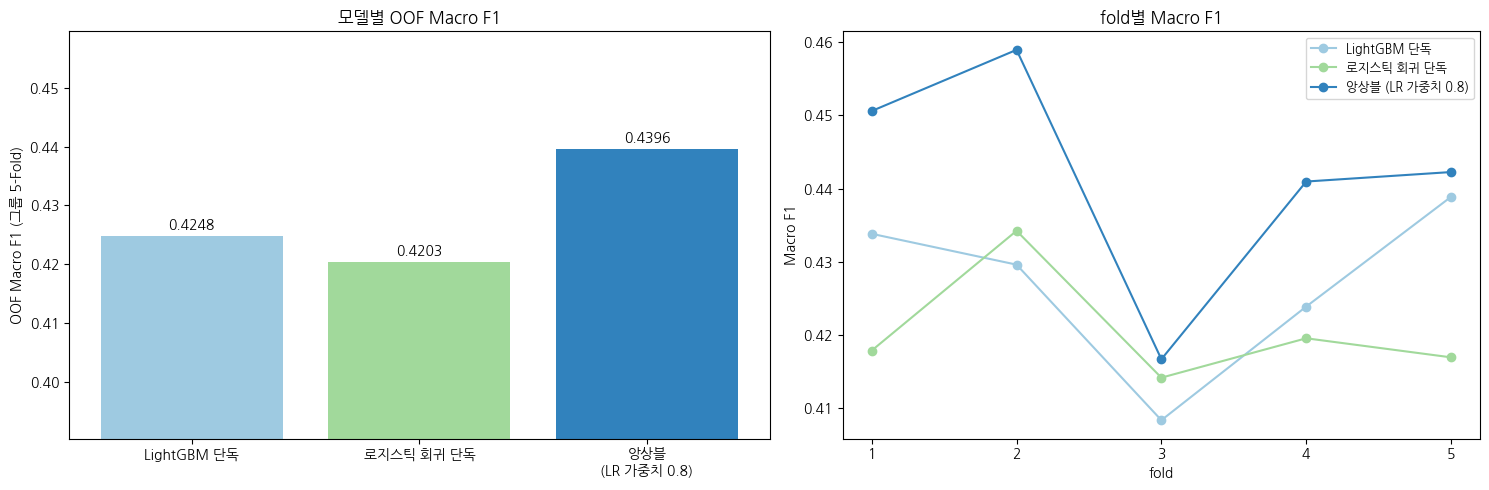

                  OOF Macro F1  fold 평균  fold 표준편차
LightGBM 단독             0.4248   0.4269     0.0105
로지스틱 회귀 단독              0.4203   0.4206     0.0071
앙상블 (LR 가중치 0.8)        0.4396   0.4419     0.0142


In [12]:
# ===== 모델 성능 비교 그래프 (9장 다음에 추가) =====
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib            # 한글 폰트 (없으면 위 pip 셀 먼저 실행)
except ImportError:
    pass
plt.rcParams['axes.unicode_minus'] = False

def f1_of(P_or_pred, idx=None):
    pred = P_or_pred if P_or_pred.ndim == 1 else P_or_pred.argmax(1)
    if idx is None:
        return f1_score(y, pred, average='macro')
    return f1_score(y[idx], pred[idx], average='macro')

# 비교할 결과 모으기 (노트북에서 이미 계산된 OOF만 사용, 재학습 없음)
results = {'LightGBM 단독': oof_lgb}
if USE_LR_BLEND:
    results['로지스틱 회귀 단독'] = oof_lr
    results[f'앙상블\n(LR 가중치 {LR_W})'] = P_oof

names = list(results)
overall = [f1_of(results[n]) for n in names]
per_fold = {n: [f1_of(results[n], va) for _, va in folds] for n in names}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.1, 1]})

# (1) 전체 OOF Macro F1 막대그래프
colors = ['#9ecae1', '#a1d99b', '#3182bd', '#08519c'][:len(names)]
bars = axes[0].bar(names, overall, color=colors)
axes[0].bar_label(bars, fmt='%.4f', padding=3)
axes[0].set_ylim(min(overall) - 0.03, max(overall) + 0.02)
axes[0].set_ylabel('OOF Macro F1 (그룹 5-Fold)')
axes[0].set_title('모델별 OOF Macro F1')

# (2) fold별 점수 (점수가 얼마나 흔들리는지)
x = np.arange(1, len(folds) + 1)
for n, c in zip(names, colors):
    axes[1].plot(x, per_fold[n], marker='o', color=c, label=n.replace('\n', ' '))
axes[1].set_xticks(x); axes[1].set_xlabel('fold'); axes[1].set_ylabel('Macro F1')
axes[1].set_title('fold별 Macro F1')
axes[1].legend(fontsize=9)

plt.tight_layout(); plt.show()

summary = pd.DataFrame({'OOF Macro F1': overall,
                        'fold 평균': [np.mean(per_fold[n]) for n in names],
                        'fold 표준편차': [np.std(per_fold[n]) for n in names]},
                       index=[n.replace('\n', ' ') for n in names]).round(4)
print(summary.to_string())

## 10. 전체 Train으로 재학습 → Test 예측

In [13]:
N_FINAL = int(np.mean(best_iters) * 1.1)     # 데이터가 1/0.8배 많아지므로 반복 수를 조금 늘림
print('최종 반복 수:', N_FINAL)

feat = TreeFeaturizer().fit(tr_all, tr_ns)                 # Train으로만 fit
X_train = feat.transform(tr_all, tr_ns, tr_stat)
X_test  = feat.transform(te_all, te_ns, te_stat)           # Test는 transform만
final_lgb = lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': N_FINAL}).fit(X_train, y)
P_test = (1 - LR_W) * final_lgb.predict_proba(X_test)

if LR_W > 0:
    lf = LinearFeaturizer().fit(tr_all, tr_ns, tr_stat)
    P_test += LR_W * make_lr().fit(lf.transform(tr_all, tr_ns, tr_stat), y).predict_proba(lf.transform(te_all, te_ns, te_stat))

test_pred = le.inverse_transform(P_test.argmax(1))

최종 반복 수: 181


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 11. 제출 파일 저장

In [14]:
assert (submission['ID'].values == test['ID'].values).all()
submission['SUBCLASS'] = test_pred
submission.to_csv('submission_lightgbm_nobias.csv', index=False, encoding='UTF-8-sig')
print(submission['SUBCLASS'].value_counts().head(10).to_string())

SUBCLASS
COAD      494
STES      277
LUSC      172
BRCA      147
KIPAN     141
SKCM      118
OV        115
PRAD      104
GBMLGG     85
UCEC       80


## 튜닝 팁 (반드시 그룹 CV 점수로만 판단)
- `num_leaves` (7~31), `colsample_bytree` (0.1~0.5), `min_child_samples` (3~20), `MIN_DF` (2~10)
- `learning_rate`를 0.02로 낮추면 대개 조금 좋아지지만 학습 시간이 늘어납니다.
- 조기 종료에 검증 fold를 쓰므로 OOF 점수가 아주 약간 낙관적일 수 있습니다.
- KIPAN/KIRC, GBMLGG/LGG는 같은 환자가 두 라벨로 존재해서 줄일 수 없는 오차가 있습니다.